# 감성 분석

- 분류 모델의 가장 대표적인 활용 방법 중 하나

- 텍스트 데이터를 긍정 또는 부정으로 나누어 분류하는 것

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from selenium import webdriver
from bs4 import BeautifulSoup
import re
import time
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
import requests
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# 맛집 상세페이지 url 정보 크롤링

In [3]:
# 크롤링할 주소
url = "https://map.kakao.com/"

In [4]:
driver = webdriver.Chrome()

# 카카오지도 접속
driver.get(url)
driver.implicitly_wait(3)

# 검색창에 검색어 입력
searchbox = driver.find_element(By.CSS_SELECTOR, "input.query")
searchbox.send_keys("신촌 맛집")

# 엔터 눌러서 결과 받아오기
searchbox.send_keys(Keys.ENTER)

# 검색 결과를 가져올 시간 대기
time.sleep(1)

# html정보 파싱
soup = BeautifulSoup(driver.page_source, "lxml")
moreviews = soup.select("a.moreview")

# 크롤링할 상세페이지 url 리스트 생성
page_urls = []

for more in moreviews:
    page = more.get("href")
    page_urls.append(page)

In [7]:
moreviews[0].get("href")

'https://place.map.kakao.com/27144649'

In [8]:
page_urls

['https://place.map.kakao.com/27144649',
 'https://place.map.kakao.com/1011256721',
 'https://place.map.kakao.com/12441959',
 'https://place.map.kakao.com/2135513146',
 'https://place.map.kakao.com/17505297',
 'https://place.map.kakao.com/10621045',
 'https://place.map.kakao.com/15937430',
 'https://place.map.kakao.com/26956113',
 'https://place.map.kakao.com/10386326',
 'https://place.map.kakao.com/20225173',
 'https://place.map.kakao.com/1165755646',
 'https://place.map.kakao.com/18287294',
 'https://place.map.kakao.com/69756475',
 'https://place.map.kakao.com/1036192129',
 'https://place.map.kakao.com/8122805']

# 상세페이지에서 리뷰 크롤링

In [28]:
res = requests.get("https://place.map.kakao.com/commentlist/v/27144649")

In [29]:
data = res.json()

In [30]:
data["comment"]["list"][0]["point"]

3

In [31]:
data["comment"]["list"][0]["contents"]

'가끔 가볼만한 식당(2.9/5.0)\n\n여유가 없는 학생들에게 고마운 식당 \n훌륭한 가성비, 보통보다 떨어지는 맛. \n정신없는 가게, 밥 먹었으면 바로 나가야하는 조급함. \n대기해야 먹을 수 있는 점. \n하지만 훌륭한 가성비. '

In [18]:
len(data["comment"]["list"])

5

In [20]:
data["comment"]["list"][-1]["commentid"]

'12317652'

In [ ]:
# 다음 리뷰 url
"https://place.map.kakao.com/commentlist/v/27144649/12317652"

In [39]:
stars = []
reviews = []

# 댓글 정보 url
base_url = "https://place.map.kakao.com/commentlist/v/"

# 위에서 수집한 15개 가게에 대해서 수집
for url in page_urls:
    last_id = ""

    # 10번 더보기 수행
    for _ in range(10):
        res = requests.get(base_url + url[28:] + "/" + last_id)
        data = res.json()

        # 별점, 리뷰 수집
        try:
            for review in data["comment"]["list"]:
                stars.append(review["point"])
                reviews.append(review.get("contents", ""))
        except KeyError:
            break

        # 더보기 시에 사용할 마지막 id
        last_id = review["commentid"]
        time.sleep(1)

In [40]:
len(reviews)

661

In [41]:
len(stars)

661

In [42]:
df = pd.DataFrame({"score" : stars, "review" : reviews})

In [43]:
df.head()

,score,review
0,3,가끔 가볼만한 식당(2.9/5.0)\n\n여유가 없는 학생들에게 고마운 식당 \n훌...
1,5,"아니 가격과 크기를 보고 말을 하셈\n현금만이니까 이 가격인거고, 카드랑 계좌이체 ..."
2,4,압도적 가성비
3,5,현금영수증 가능하고 매장 깔끔하기까지... 저가격에 현금 밖에 안된다고 탈세 타령 ...
4,3,까먹고 사진안찍음\n진짜 이런 가성비집은 없음\n3조각 8천원 시키면 왠만한 돼지들...


In [44]:
df.to_csv("./data/kakaomap.csv", index = False)

In [45]:
# 4점 이상 리뷰는 긍정 리뷰, 3점 이하는 부정 리뷰로 평가
df["y"] = df["score"].map(lambda x: 1 if x > 3 else 0)

In [46]:
df.head()

,score,review,y
0,3,가끔 가볼만한 식당(2.9/5.0)\n\n여유가 없는 학생들에게 고마운 식당 \n훌...,0
1,5,"아니 가격과 크기를 보고 말을 하셈\n현금만이니까 이 가격인거고, 카드랑 계좌이체 ...",1
2,4,압도적 가성비,1
3,5,현금영수증 가능하고 매장 깔끔하기까지... 저가격에 현금 밖에 안된다고 탈세 타령 ...,1
4,3,까먹고 사진안찍음\n진짜 이런 가성비집은 없음\n3조각 8천원 시키면 왠만한 돼지들...,0


In [47]:
# 레이블값 비율
df["y"].value_counts()

y
1    471
0    190
Name: count, dtype: int64

# 텍스트 전처리

## 한글 추출

In [48]:
def text_cleaning(text:str):
    '''
    텍스트 정제 함수
    한글 이외의 문자는 전부 제거
    '''
    # 한글 이외의 문자들 추출
    han = re.compile("[^ ㄱ-ㅣ가-힣]+")
    # 한글 이외의 문자들 제거
    text = han.sub(" ", text)

    return text

In [50]:
df["ko_text"] = df["review"].map(text_cleaning)

In [51]:
df.head()

,score,review,y,ko_text
0,3,가끔 가볼만한 식당(2.9/5.0)\n\n여유가 없는 학생들에게 고마운 식당 \n훌...,0,가끔 가볼만한 식당 여유가 없는 학생들에게 고마운 식당 훌륭한 가성비 보통보다 ...
1,5,"아니 가격과 크기를 보고 말을 하셈\n현금만이니까 이 가격인거고, 카드랑 계좌이체 ...",1,아니 가격과 크기를 보고 말을 하셈 현금만이니까 이 가격인거고 카드랑 계좌이체 안...
2,4,압도적 가성비,1,압도적 가성비
3,5,현금영수증 가능하고 매장 깔끔하기까지... 저가격에 현금 밖에 안된다고 탈세 타령 ...,1,현금영수증 가능하고 매장 깔끔하기까지 저가격에 현금 밖에 안된다고 탈세 타령 광광...
4,3,까먹고 사진안찍음\n진짜 이런 가성비집은 없음\n3조각 8천원 시키면 왠만한 돼지들...,0,까먹고 사진안찍음 진짜 이런 가성비집은 없음 조각 천원 시키면 왠만한 돼지들 배터...


In [52]:
df.shape

(661, 4)

In [55]:
df = df[df["ko_text"].str.len() > 0]

In [56]:
df.head()

,score,review,y,ko_text
0,3,가끔 가볼만한 식당(2.9/5.0)\n\n여유가 없는 학생들에게 고마운 식당 \n훌...,0,가끔 가볼만한 식당 여유가 없는 학생들에게 고마운 식당 훌륭한 가성비 보통보다 ...
1,5,"아니 가격과 크기를 보고 말을 하셈\n현금만이니까 이 가격인거고, 카드랑 계좌이체 ...",1,아니 가격과 크기를 보고 말을 하셈 현금만이니까 이 가격인거고 카드랑 계좌이체 안...
2,4,압도적 가성비,1,압도적 가성비
3,5,현금영수증 가능하고 매장 깔끔하기까지... 저가격에 현금 밖에 안된다고 탈세 타령 ...,1,현금영수증 가능하고 매장 깔끔하기까지 저가격에 현금 밖에 안된다고 탈세 타령 광광...
4,3,까먹고 사진안찍음\n진짜 이런 가성비집은 없음\n3조각 8천원 시키면 왠만한 돼지들...,0,까먹고 사진안찍음 진짜 이런 가성비집은 없음 조각 천원 시키면 왠만한 돼지들 배터...


In [57]:
df.shape

(533, 4)

## 텍스트 임베딩

- 텍스트 데이터를 연산이 가능한 피처로 변환

### TF-IDF(Term Frequency-Inverse Document Frequency)

- 단어의 빈도와 역 문서 빈도를 사용하여 각 단어들의 중요도를 가중치로 주는 방법

- TF : 1개의 문서 내에서 특정 단어의 등장 빈도
    - 문서 d에서 단어 t가 등장한 횟수 / 문서 d에 등장한 모든 단어의 수
 
- DF : 특정 단어가 등장한 문서의 수
    - 단어 t를 포함하는 문서의 수 / 총 문서의 개수
 
- IDF : DF에 반비례하는 수
    - log(총 문서의 개수 / 단어 t를 포함하는 문서의 수)
 
- 다른 문서들에서는 많이 등장하지 않았지만 현재 문서에서는 많이 등장하는 단어를 의미
    - 해당 단어가 현재 문서에서 얼마나 중요한지를 계산하는 방법

In [58]:
x = df["ko_text"]
y = df["y"]

In [59]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, stratify = y,
                                                    random_state = 26)

In [60]:
x_train.shape, x_test.shape

((373,), (160,))

In [61]:
tfidf = TfidfVectorizer()
tf_train = tfidf.fit_transform(x_train)
tf_test = tfidf.transform(x_test)

In [62]:
tf_train.shape

(373, 3530)

# 모델 훈련

In [66]:
logi = LogisticRegression()
logi.fit(tf_train, y_train)

LogisticRegression()

In [67]:
pred = logi.predict(tf_test)
proba = logi.predict_proba(tf_test)[:, 1]

In [68]:
print(accuracy_score(y_test, pred))
print(f1_score(y_test, pred))

0.7
0.8235294117647058


In [69]:
logi.score(tf_test, y_test)

0.7

In [70]:
comat = confusion_matrix(y_test, pred)
print(comat)

[[  0  48]
 [  0 112]]


In [71]:
pd.DataFrame({"text" : x_test, "pred" : pred})

,text,pred
50,찐 가성비 샤인머스켓 보다는 제주녹차 카모마일 내 취향 코코넛 카스타드 많이 들어...,1
491,떡 맛있음 찹쌀떡 말랑함,1
555,알바 너무 친절해서 팁문화가 있었다면 팁 주고 싶을 정도로 좋은 서비스 받았어요 ...,1
508,호박떡 맛있어요 친구 집 놀러가면서 사갔는데 친구가 완전 푹 빠져서 제가 놀러갈 ...,1
135,프랜차이즈 시 인 건 알겠는데 내가 아는 국밥 맛이 아니여,1
...,...,...
158,국물은 쏘쏘 고기잡내나서 좀 별로 두번은 안갈거같아요,1
516,괜찮습니다,1
180,존맛 오징어볶음 불향 제대로 나고 고등어도 크고 실해요 ㅠ 가시도 앵간 다 발라져있...,1
433,맛있게 잘 먹고 계산서를 보니 계산했던 금액보다 만원이 더 나옴 문의하니 주문에 없...,1


# 모델 최적화

In [72]:
df[df["y"] == 0].shape

(160, 4)

In [74]:
df[df["y"] == 1].shape

(373, 4)

In [73]:
# 1:1 비율로 랜덤 샘플링 수행
pos_idx = df[df["y"] == 1].sample(160, random_state = 26).index.tolist()
neg_idx = df[df["y"] == 0].index.tolist()

In [75]:
pos_idx

[87,
 99,
 111,
 544,
 378,
 640,
 8,
 644,
 355,
 465,
 538,
 623,
 176,
 523,
 321,
 198,
 350,
 219,
 506,
 241,
 86,
 270,
 578,
 51,
 58,
 200,
 97,
 595,
 401,
 45,
 304,
 430,
 163,
 561,
 543,
 630,
 590,
 648,
 545,
 443,
 136,
 266,
 365,
 423,
 259,
 251,
 434,
 206,
 30,
 185,
 558,
 96,
 556,
 539,
 323,
 320,
 339,
 286,
 348,
 352,
 131,
 507,
 342,
 499,
 536,
 139,
 471,
 517,
 454,
 80,
 210,
 252,
 203,
 500,
 600,
 474,
 437,
 455,
 2,
 478,
 25,
 449,
 408,
 518,
 574,
 622,
 563,
 199,
 616,
 593,
 520,
 485,
 215,
 426,
 394,
 513,
 228,
 554,
 479,
 302,
 19,
 502,
 606,
 173,
 577,
 246,
 296,
 79,
 415,
 472,
 269,
 36,
 214,
 649,
 360,
 399,
 356,
 264,
 377,
 421,
 68,
 657,
 601,
 65,
 445,
 347,
 242,
 260,
 247,
 392,
 190,
 403,
 236,
 74,
 646,
 335,
 404,
 217,
 44,
 405,
 621,
 213,
 155,
 451,
 357,
 239,
 224,
 88,
 349,
 468,
 178,
 387,
 195,
 52,
 81,
 46,
 115,
 226,
 441,
 603]

In [76]:
random_idx = pos_idx + neg_idx

In [77]:
len(random_idx)

320

In [80]:
sample_x = x[random_idx]
sample_y = df["y"][random_idx]

In [82]:
len(sample_x), len(sample_y)

(320, 320)

In [83]:
x_train, x_test, y_train, y_test = train_test_split(sample_x, sample_y, stratify = sample_y,
                                                    test_size = 0.3, random_state = 26)

In [84]:
tfidf = TfidfVectorizer()
tf_train = tfidf.fit_transform(x_train)
tf_test = tfidf.transform(x_test)

In [86]:
tf_train.shape

(224, 2428)

In [87]:
logi = LogisticRegression()
logi.fit(tf_train, y_train)

LogisticRegression()

In [88]:
pred = logi.predict(tf_test)

In [89]:
print(accuracy_score(y_test, pred))
print(f1_score(y_test, pred))

0.7083333333333334
0.6888888888888889


In [90]:
comat = confusion_matrix(y_test, pred)
comat

array([[37, 11],
       [17, 31]], dtype=int64)

In [91]:
logi.score(tf_train, y_train)

0.9866071428571429

In [92]:
pd.DataFrame({"text" : x_test, "pred" : pred, "ans" : y_test})

,text,pred,ans
145,순대국밥 인 그 가격에 비해 건더기 너무 부실해요 맛도 그냥 별로인 순대국밥...,0,0
224,토요일 점심 혼자 방문했는데도 흔쾌히 인석으로 안내받음 볶음밥 주문 정말 맛...,0,1
599,가게 인테리어 깔끔 런치세트 먹었는데 카레가 인스턴트 로제파스타 소스 맛 양...,1,0
401,사장님 친절하시구 낙지도 실하네요 재방문 할거 같아요,0,1
630,밀크티가 종류도 다양하고 맛있어요,1,1
...,...,...,...
517,대기 분 왜 대기있는지 이해될정도로 만족도 높음 가성비 맛있고 괜찮았음 ...,1,1
554,리뷰 한 번도 써본 적 없는데 직원분들한테 감동받아서 리뷰 써요 제가 갑자기 지...,1,1
66,유명해서 기대했는데 맛은 기대이하 기냥 평범하고 저렴한 한국식파이맛인듯,0,0
299,맛은 있는데 직원이 팁을 반 강요하네요 좀 별로네요 직원 월급을 안주나요,0,0


In [98]:
# 테스트
query = tfidf.transform(["잘도 그러겠다"])

In [99]:
logi.predict(query)

array([0], dtype=int64)

# 키워드 분석

- 로지스틱 회귀 모델의 피처 영향력으로 가장 높은 영향력을 가지고 있는 단어 찾기

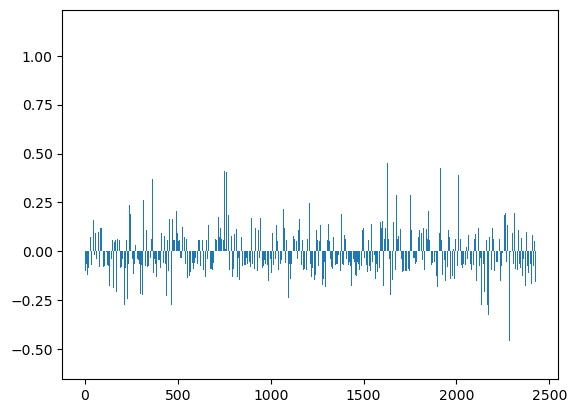

In [100]:
plt.figure()

plt.bar(range(len(logi.coef_.flatten())), logi.coef_.flatten())
plt.show()

In [102]:
logi.coef_.flatten().shape

(2428,)

In [103]:
# 회귀 모델의 계수를 내림차순으로 정렬
coef_pos_idx = sorted(((value, idx) for idx, value in enumerate(logi.coef_.flatten())),
                      reverse = True)

In [104]:
coef_pos_idx[:5]

[(1.1498213957101489, 768),
 (0.7240695955867356, 2138),
 (0.5357308389754819, 749),
 (0.5090855755852186, 1749),
 (0.4884092524219564, 368)]

In [105]:
# 상위 20개 긍정 형태소
for value, idx in coef_pos_idx[:20]:
    print(tfidf.get_feature_names_out()[idx], value)

맛있어요 1.1498213957101489
최고 0.7240695955867356
맛잇음 0.5357308389754819
인도커리 0.5090855755852186
낙지찜 0.4884092524219564
오징어볶음 0.45407551028302173
너무 0.4263574690940336
조금 0.42571532867925477
좋아요 0.4255743218272432
추천합니당 0.41062406256096395
맛있게먹었음 0.41062406256096395
맛나용 0.41062406256096395
마늘빵원탑 0.41062406256096395
돼지가되 0.41062406256096395
고등어진짜맛있어요 0.41062406256096395
맛있다 0.4065822798246963
중국집 0.3913297589151094
좋고 0.3835218433351686
맛도 0.377027294917177
가성비 0.36927529903679196


In [106]:
# 상위 20개 부정 형태소
for value, idx in coef_pos_idx[:-20:-1]:
    print(tfidf.get_feature_names_out()[idx], value)

많이 -0.5684372678758978
노맛 -0.49418812232278136
펀킨파이 -0.45962419997136533
별로 -0.4418236939275285
별로에요 -0.4352351702442647
맛은 -0.42723156197171996
낫밷 -0.3913366707808058
맥주 -0.3913366707808058
무난했어요 -0.3913366707808058
빈약해요 -0.3913366707808058
하나도 -0.3530868971701186
신고 -0.3316032401060188
불친절합니다 -0.3280641846405471
친절 -0.32786571058955266
재구매의사 -0.32486207054459304
카드 -0.3105815922841011
훌륭한 -0.3085116126401033
좋은 -0.30070448732615324
반찬이 -0.2955203593161908
